In [1]:
# --- project root: run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: <project folder>


# 18 — Round 7: SegFormer v7 = the v6 model trained on 72 regions (20 new training regions)

**Same network and settings as v6** (all 12 months + 18 year statistics, `train_lib_r6.py`); the only change is the data:
`data_r7` = the 38 old training regions + 20 new ones (rice paddies labelled Cropland, natural wetlands, grass/shrub,
tropical cities). Validation and test regions are the same as for v5 and v6, so the scores are directly comparable.

What to look at: **Wetland and Cropland IoU** (fewer rice fields called Wetland), **Grass/Shrub IoU**, and later the
Nujivid / Hanuman Junction test in notebook 15 (`RUN_V6 = "runs/C_segformer_v7"`).

Nothing existing is changed: results go to `runs/C_segformer_v7/`.

## 1. Settings

In [2]:
CFG = dict(
    RUN_NAME="C_segformer_v7", MODEL_NAME="SegFormer v7 (v6 + 20 new regions)",
    ARCH="temporal_segformer_mitb2", FEATURES="12months+yearstats18",
    DATA="data_r7", WEIGHTS="imagenet",
    EPOCHS=60, WARMUP_EPOCHS=5, BATCH_SIZE=8, EVAL_BATCH=2,
    LR=6e-5, LR_NEW=1e-3, WEIGHT_DECAY=0.01, PATIENCE=12, LOSS="lovasz",
    NOISE_DB=2.0, ROLL=True, MONTH_DROP=0.1, TEMP_DIM=24, FUSE_DIM=32,
    NUM_WORKERS=0, SEED=42)
# Out of GPU memory? -> BATCH_SIZE=4 (and restart the kernel).

## 2. Setup

In [3]:
import json, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from preprocess import CLASSES, COLORS, IGNORE, load_stats
from train_lib_r6 import *

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
RUN = Path("runs") / CFG["RUN_NAME"]; RUN.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
DATA = Path(CFG["DATA"])
mstats = load_stats(DATA / "norm_stats.json")                 # monthly VV, VH, VV-VH mean / std (as v5)
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)
print("device:", DEV, "|", torch.cuda.get_device_name(0) if DEV == "cuda" else "no GPU - training would be very slow")
print(index.split.value_counts().to_dict())

device: cuda | NVIDIA RTX A6000
{'train': 1450, 'val': 128, 'test': 96}


## 3. Step 2 — the 18 year statistics
Computed per pixel over the 12 months. Their average and spread over the training patches are used to rescale them
(computed once from 300 training patches and saved as `data_r7/norm_stats_r6_yearstats.json`).

In [4]:
ystats = year_stat_norm(index, DATA)
display(pd.DataFrame({"mean": ystats["mean"], "std": ystats["std"]}, index=ystats["names"]).round(2).T)

year-statistics normalisation:   0%|          | 0/300 [00:00<?, ?it/s]

,VV_median,VV_p10,VV_p90,VV_min,VV_max,VV_range,VH_median,VH_p10,VH_p90,VH_min,VH_max,VH_range,VV_VH_median,VV_VH_p10,VV_VH_p90,VV_VH_min,VV_VH_max,VV_VH_range
mean,-11.09,-12.89,-9.33,-13.76,-8.46,5.29,-18.59,-20.68,-16.69,-21.65,-15.83,5.82,7.49,5.48,9.58,4.52,10.66,6.14
std,4.66,4.90,4.54,5.02,4.57,2.57,4.95,5.20,4.80,5.35,4.83,3.00,2.08,2.04,2.37,2.15,2.66,2.43


### What the classes look like over the year
Median VH and VV of every class over the 12 months (training patches, sample of pixels). The shaded band is the 10–90 % range.
**This is the information v6 can now use and v5 could not:** classes that have the same average can still have a different curve.

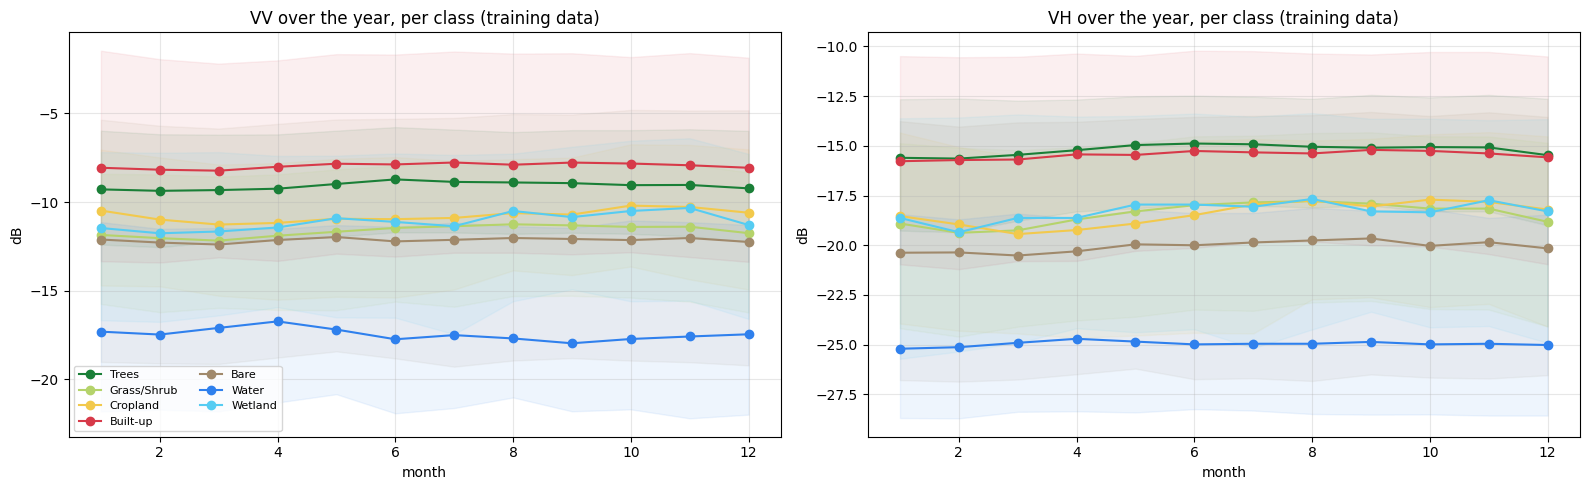

In [5]:
files = index[index.split == "train"].file
files = files.sample(min(120, len(files)), random_state=0)
curves = {c: [] for c in range(len(CLASSES))}
rng = np.random.default_rng(0)
for f in files:
    d = np.load(DATA / f); x, y = d["x"].astype(np.float32), d["y"]
    for c in range(len(CLASSES)):
        r, cc = np.nonzero(y == c)
        if len(r):
            k = rng.choice(len(r), min(40, len(r)), replace=False)
            curves[c].append(x[:, :2, r[k], cc[k]])               # (12, 2, n)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for c, col in enumerate(COLORS):
    if not curves[c]: continue
    v = np.concatenate(curves[c], 2)
    for b, name in enumerate(["VV", "VH"]):
        med = np.nanmedian(v[:, b], 1); lo, hi = np.nanpercentile(v[:, b], [10, 90], 1)
        ax[b].plot(range(1, 13), med, color=col, marker="o", label=CLASSES[c]); ax[b].fill_between(range(1, 13), lo, hi, color=col, alpha=0.08)
for b, name in enumerate(["VV", "VH"]):
    ax[b].set_title(f"{name} over the year, per class (training data)"); ax[b].set_xlabel("month"); ax[b].set_ylabel("dB"); ax[b].grid(alpha=0.3)
ax[0].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.savefig(RUN / "class_curves.png", dpi=120); plt.show()

## 4. Data and model

In [6]:
train_dl, val_dl = make_loaders(CFG, DATA, index)
model = build_model(CFG, mstats, ystats, CFG["WEIGHTS"]).to(DEV)
loss_fn = make_loss(CFG, mstats)
print(f"parameters: {count_params(model):.1f} M  (same as v6) - temporal encoder + fusion: "
      f"{(count_params(model.temporal) + count_params(model.fuse)) * 1000:.1f} k")

# quick check: one batch through the model
x, m, y = next(iter(train_dl))
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    out = model(x.to(DEV), m.to(DEV))
print("input", tuple(x.shape), "(batch, months, bands, H, W) | output", tuple(out.shape), "(batch, classes, H, W)")

loading val:   0%|          | 0/128 [00:00<?, ?it/s]

train patches 1450 | val patches 128 (x 12 months each)
parameters: 24.8 M  (same as v6) - temporal encoder + fusion: 7.1 k
input (8, 12, 3, 256, 256) (batch, months, bands, H, W) | output (8, 7, 256, 256) (batch, classes, H, W)


## 5. Train
Resumes automatically from `last.pth` if the kernel stops. One epoch ≈ a few minutes on the GPU.

In [7]:
history = train(model, CFG, RUN, train_dl, val_dl, loss_fn)

epoch 0:   0%|          | 0/181 [00:00<?, ?it/s]

ep  0 | train 1.865 | val 1.472 | OA 0.759 | mIoU 0.521  *best* | 101s


epoch 1:   0%|          | 0/181 [00:00<?, ?it/s]

ep  1 | train 1.296 | val 1.385 | OA 0.765 | mIoU 0.542  *best* | 98s


epoch 2:   0%|          | 0/181 [00:00<?, ?it/s]

ep  2 | train 1.161 | val 1.329 | OA 0.778 | mIoU 0.579  *best* | 98s


... (58 outputs left out)

epoch 32:   0%|          | 0/181 [00:00<?, ?it/s]

ep 32 | train 0.615 | val 1.195 | OA 0.805 | mIoU 0.619 | 98s


epoch 33:   0%|          | 0/181 [00:00<?, ?it/s]

ep 33 | train 0.615 | val 1.204 | OA 0.807 | mIoU 0.623 | 98s
Early stopping.
Done. Best val mIoU: 0.6417


## 6. Results on validation (best checkpoint)

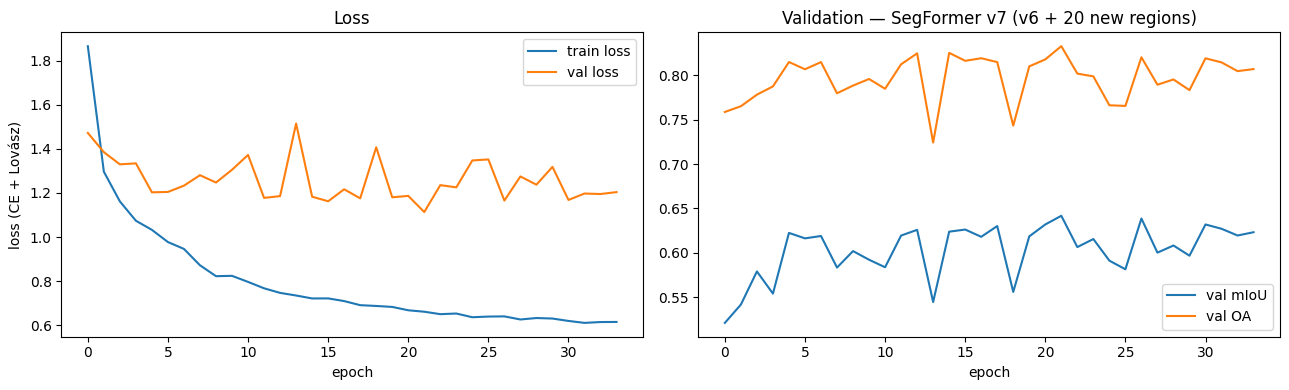

SegFormer v7 (v6 + 20 new regions) - val: OA 0.833 | mIoU 0.642 | best / worst month mIoU 0.643 / 0.640 (spread 0.003)


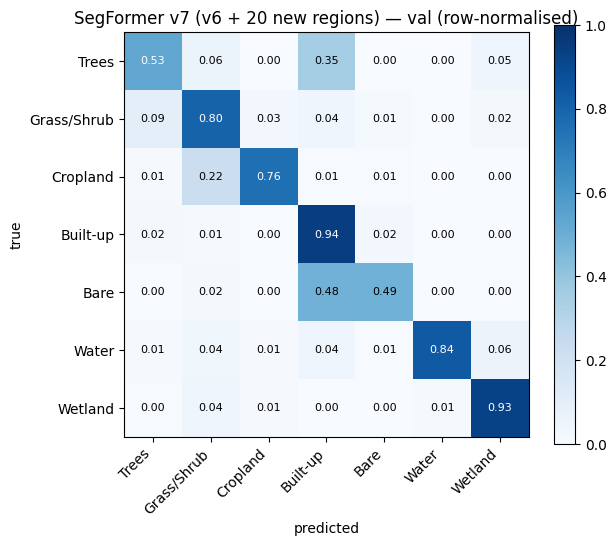

Validation, v5 vs v6 vs v7


,v5 IoU,v6 IoU,v7 IoU,v7 - v6
Trees,0.413,0.441,0.420,-0.021
Grass/Shrub,0.676,0.705,0.673,-0.032
Cropland,0.661,0.693,0.693,-0.000
Built-up,0.780,0.790,0.792,0.002
Bare,0.266,0.291,0.280,-0.011
Water,0.737,0.751,0.757,0.006
Wetland,0.851,0.879,0.876,-0.003
mIoU,0.626,0.650,0.642,-0.008


In [8]:
plot_curves(RUN, CFG["MODEL_NAME"])
model.load_state_dict(torch.load(RUN / "best.pth", map_location=DEV))
val_table, val_month = report(model, CFG, RUN, val_dl, "val")

v5 = json.load(open("runs/C_segformer_v5/metrics.json")); v6 = json.load(open("runs/C_segformer_v6/metrics.json"))
cmp = pd.DataFrame({"v5 IoU": pd.Series(v5["per_class_iou"]), "v6 IoU": pd.Series(v6["per_class_iou"]),
                    "v7 IoU": val_table["IoU"].drop("mean")})
cmp.loc["mIoU"] = [v5["val_miou"], v6["val_miou"], val_table.loc["mean", "IoU"]]
cmp["v7 - v6"] = cmp["v7 IoU"] - cmp["v6 IoU"]
print("Validation, v5 vs v6 vs v7"); display(cmp.round(3))

## 7. Do the months differ now?
v5's and v6's maps were almost identical in every month. Below: mIoU per month (validation) and four months of one validation tile.

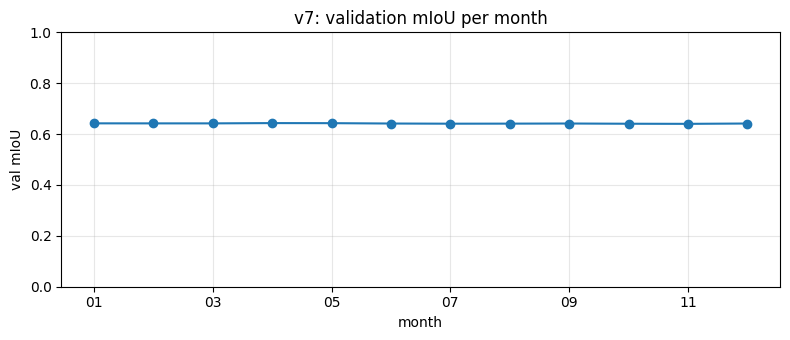

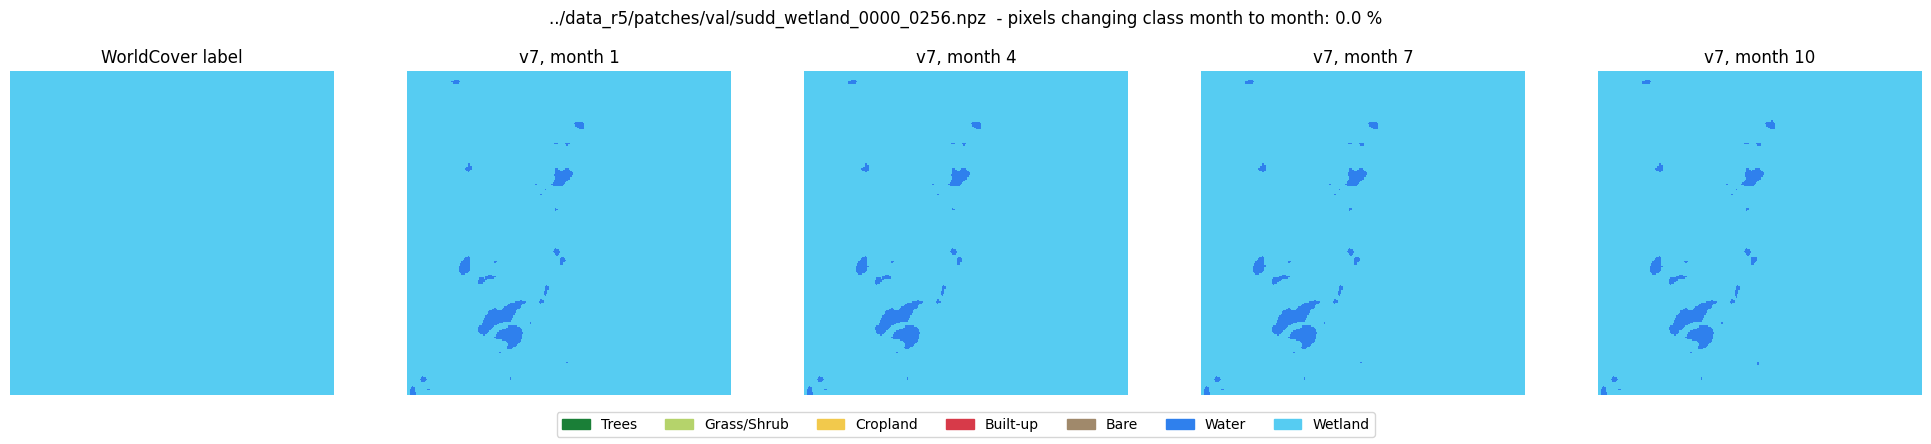

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
val_month.plot(ax=ax, marker="o"); ax.set_ylim(0, 1); ax.set_xlabel("month"); ax.set_ylabel("val mIoU"); ax.grid(alpha=0.3)
ax.set_title("v7: validation mIoU per month"); plt.tight_layout(); plt.show()

from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
ds = val_dl.dataset
k = int(np.argmax([float((y_ == 2).float().mean() + (y_ == 6).float().mean()) for y_ in ds.ys]))   # a tile with crop / wetland
x, y = ds[k]
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    e = model.encode(x[None].to(DEV))
    preds = [model.decode(e, torch.tensor([m], device=DEV)).argmax(1)[0].cpu().numpy() for m in range(12)]
changed = np.mean([(preds[m] != preds[m - 1]).mean() for m in range(1, 12)]) * 100
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
ax[0].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); ax[0].set_title("WorldCover label")
for a, m in zip(ax[1:], [0, 3, 6, 9]):
    a.imshow(preds[m], cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); a.set_title(f"v7, month {m + 1}")
for a in ax: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7)
fig.suptitle(f"{ds.files[k]}  - pixels changing class month to month: {changed:.1f} %")
plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.savefig(RUN / "val_months_example.png", dpi=110); plt.show()

## 8. Test set (final exam — only for reporting, not for choosing settings)
Same 6 test regions as v5 (OA 0.837, mIoU 0.722) and v6 (values read from `runs/C_segformer_v6/metrics.json`).

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

SegFormer v7 (v6 + 20 new regions) - test: OA 0.807 | mIoU 0.676 | best / worst month mIoU 0.679 / 0.674 (spread 0.005)


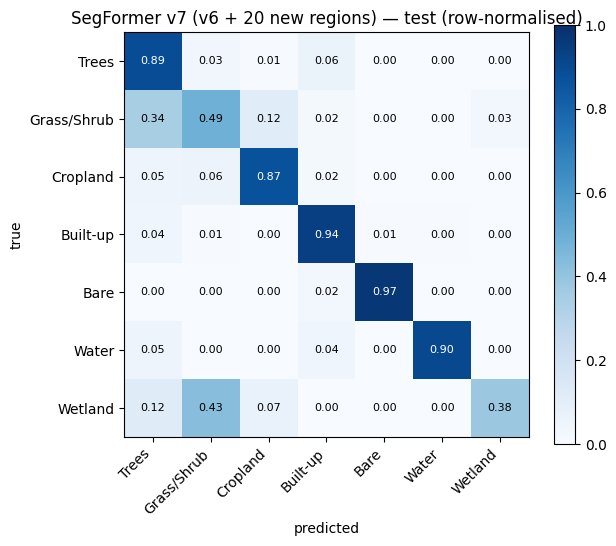

,v5 IoU,v6 IoU,v7 IoU,v7 - v6
Trees,0.686,0.695,0.641,-0.054
Grass/Shrub,0.487,0.503,0.374,-0.129
Cropland,0.716,0.714,0.707,-0.007
Built-up,0.828,0.842,0.842,-0.000
Bare,0.970,0.969,0.963,-0.006
Water,0.819,0.848,0.844,-0.004
Wetland,0.547,0.540,0.358,-0.182
mIoU,0.722,0.730,0.676,-0.054


saved: ['best.pth', 'class_curves.png', 'config.json', 'curves.png', 'history.csv', 'last.pth', 'metrics.json', 'test_confusion.png', 'test_per_class.csv', 'val_confusion.png', 'val_months_example.png', 'val_per_class.csv']


In [10]:
test_ds = EvalSeries(index[index.split == "test"].file, DATA, "loading test")
test_dl = torch.utils.data.DataLoader(test_ds, CFG["EVAL_BATCH"], shuffle=False)
test_table, test_month = report(model, CFG, RUN, test_dl, "test")
v5_test = pd.Series({"Trees": .686, "Grass/Shrub": .487, "Cropland": .716, "Built-up": .828, "Bare": .970, "Water": .819, "Wetland": .547})
t = pd.DataFrame({"v5 IoU": v5_test, "v6 IoU": pd.Series(v6.get("test_per_class_iou", {})), "v7 IoU": test_table["IoU"].drop("mean")})
t.loc["mIoU"] = [0.722, v6.get("test_miou", np.nan), test_table.loc["mean", "IoU"]]; t["v7 - v6"] = t["v7 IoU"] - t["v6 IoU"]
display(t.round(3))
print("saved:", sorted(p.name for p in RUN.iterdir()))

✅ **Share with me:** the training curves, the v5 / v6 / v7 tables, and the per-month plot.
Then test v7 on Nujivid / Hanuman Junction in notebook 15: set `RUN_V6 = "runs/C_segformer_v7"` (the model stores its own
normalisation, so nothing else needs to change) — the "v6" columns then show v7.